# Diabetics

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from scipy.stats.mstats import winsorize

# dataset loading
df = pd.read_csv("diabetes.csv")



# missing values and summary statistics
basic_info = df.info()
missing_values = df.isnull().sum()
summary_stats = df.describe(include='all')

missing_values, summary_stats

# Separazione dei casi con glyhb mancante
df_missing_glyhb = df[df['glyhb'].isnull()].copy()
df = df[~df['glyhb'].isnull()].copy()  # Rimozione dei missing da df centrale


# Conversione categoriche a 'category' dtype
categorical_cols = ['gender', 'location', 'frame']
for col in categorical_cols:
    df[col] = df[col].astype('category')

# Rename problematic column names
df = df.rename(columns={
    'stab.glu': 'stab_glu',})

# Calcolo della diagnosi (glyhb > 7.0)
df['diagnosis'] = (df['glyhb'] > 7.0).astype('category')

# Calcolo del BMI
df['bmi'] = (df['weight'] * 0.453592) / ((df['height'] * 0.0254) ** 2)

# Sostituzione dei valori mancanti di bp.2s e bp.2d con bp.1s e bp.1d
df['bp.2s_filled'] = df['bp.2s'].fillna(df['bp.1s'])
df['bp.2d_filled'] = df['bp.2d'].fillna(df['bp.1d'])

# Calcolo delle medie pressorie
df['bp_s_mean'] = ((df['bp.1s'] + df['bp.2s_filled']) / 2).round()
df['bp_d_mean'] = ((df['bp.1d'] + df['bp.2d_filled']) / 2).round()

# Calcolo Waist-Hip Ratio
df['whr'] = df['waist'] / df['hip']

# Rimozione colonne intermedie
df.drop(columns=['bp.2s_filled', 'bp.2d_filled', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d'], inplace=True)


# Filtro: tiene solo le righe complete tranne in variabili rilevanti
excluded = ['location', 'height', 'frame', 'gender', 'waist', 'time.ppn']
df_clean = df[df.drop(columns=excluded).notnull().all(axis=1)].copy()

# Subset finale per modellazione
df_model = df_clean[[
    'chol',
    'age',
    'stab_glu',
    'hdl',
    'ratio',
    'bmi',
    'whr',
    'bp_s_mean',
    'bp_d_mean',
    'diagnosis'
]].copy()

# Verifica finale
print("Shape df_model:", df_model.shape)
print("Missing values in df_model:\n", df_model.isnull().sum())

df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    object 
 7   age       403 non-null    int64  
 8   gender    403 non-null    object 
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    object 
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 non-null    float64
 16  waist     401 non-null    float64
 17  hip       401 non-null    float64
 18  time.ppn  400 non-null    float64
dtypes: float64(13), int64(3), object(3)
memory usage: 59.9+ KB
Shape df_mod

C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.histplot(
C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.histplot(
C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.histplot(
C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.histplot(
C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  sns.histplot(
C:\Users\david\AppData\Local\Temp\ipykernel_25464\2160898427.py:23: UserWarning: The palette list has mor

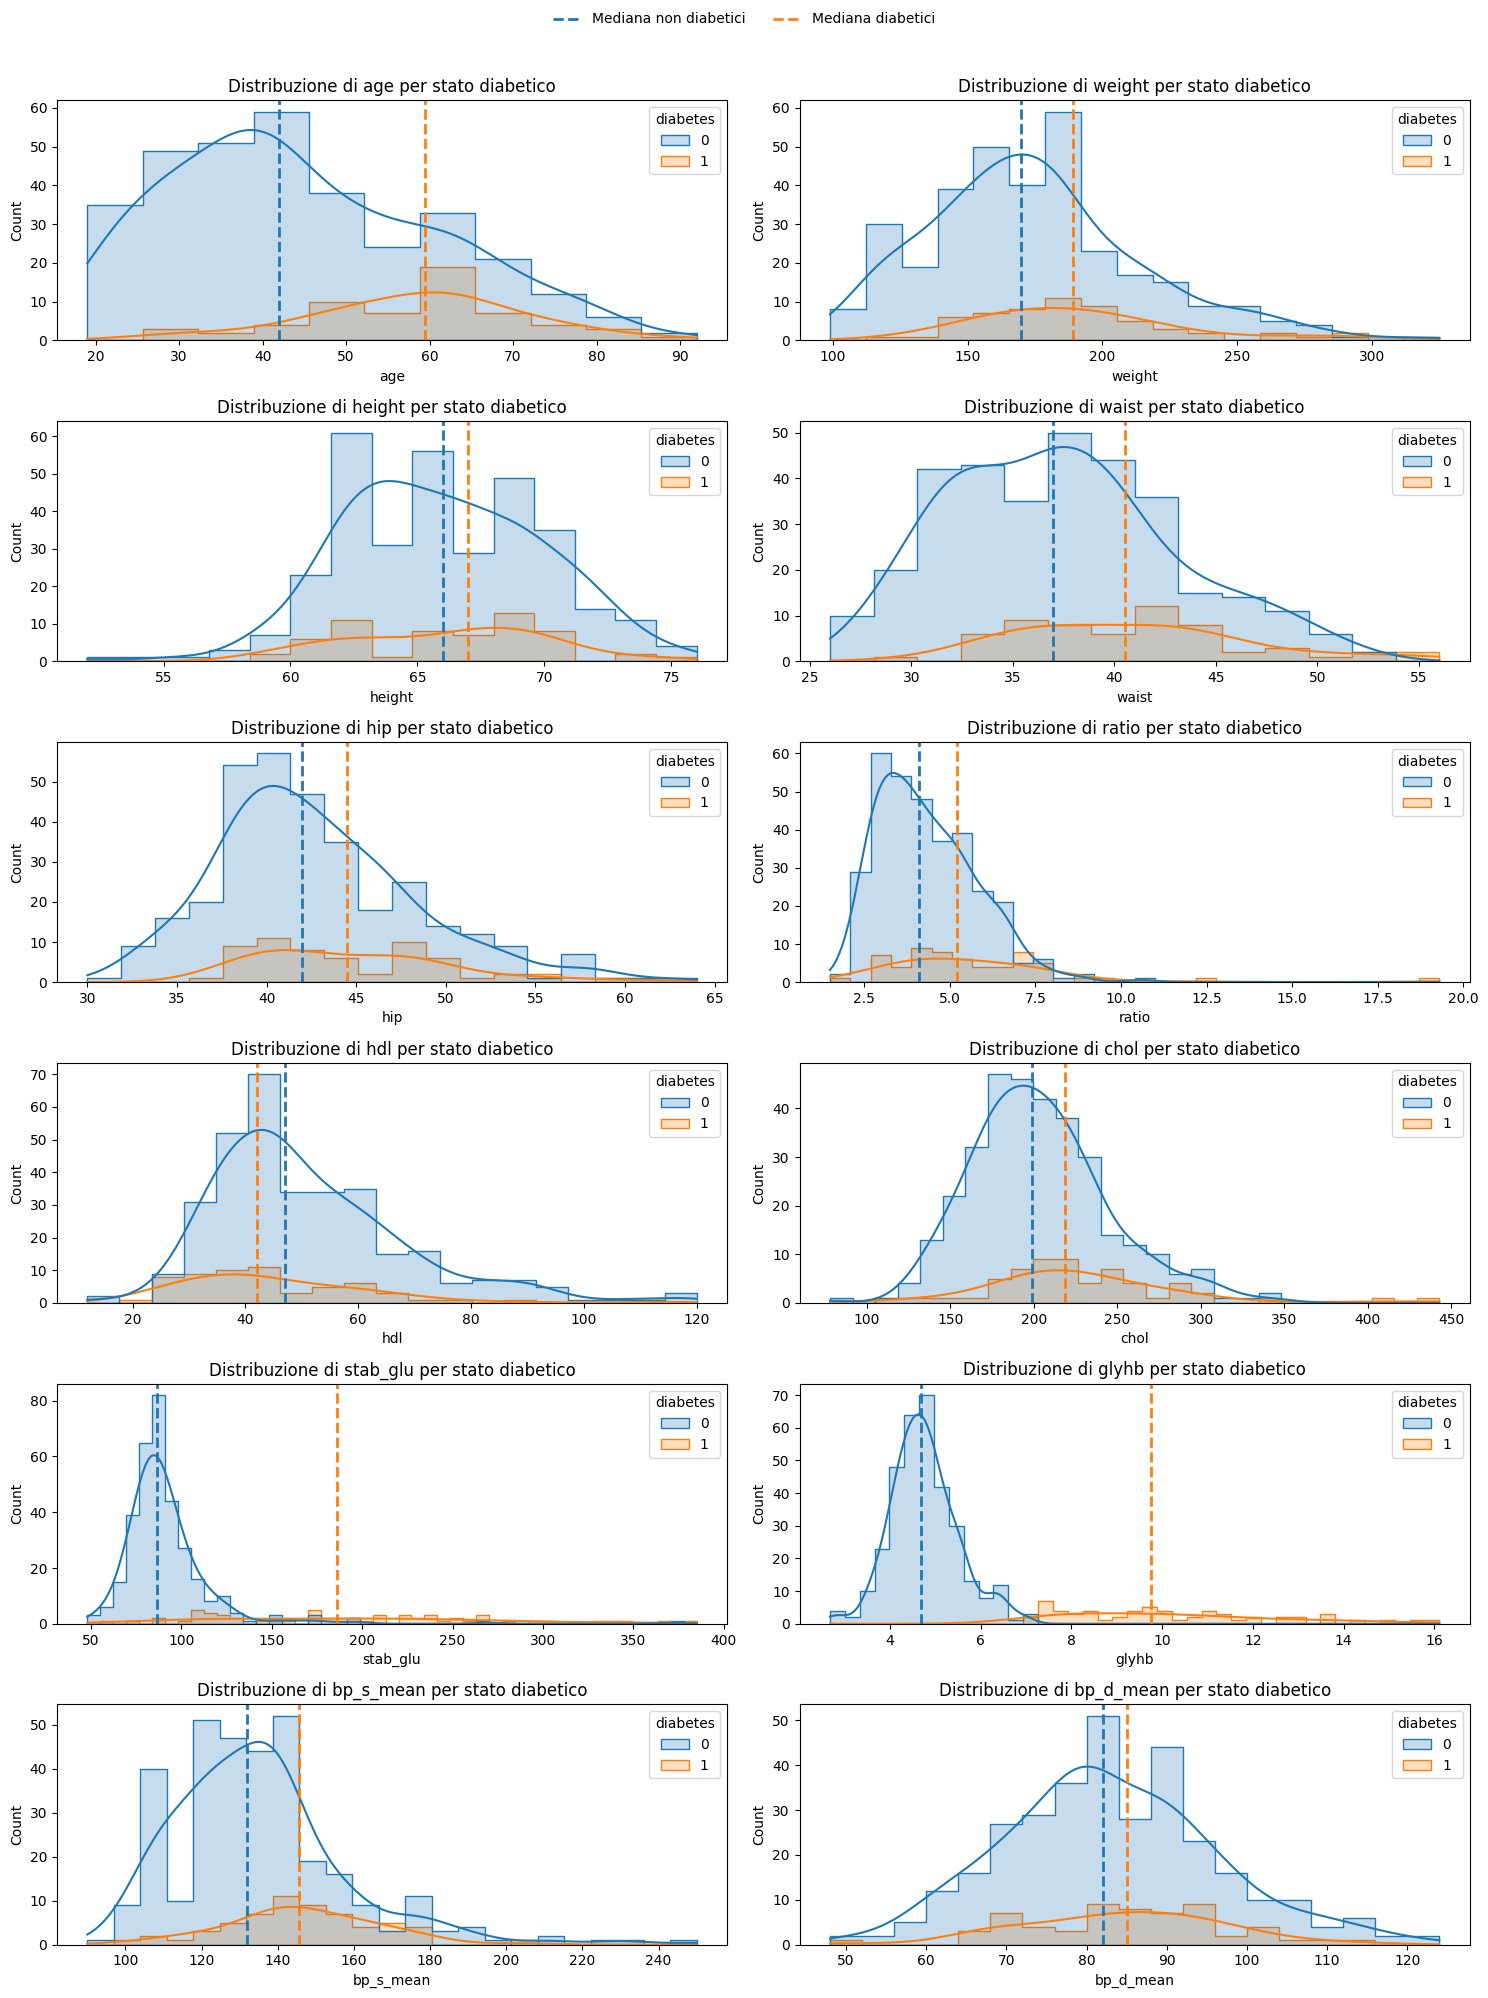

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Crea la variabile binaria di outcome
df['diabetes'] = np.where(df['glyhb'] > 7.0, 1, 0)

# Variabili continue da plottare
continuous_vars = [
    'age', 'weight', 'height', 'waist', 'hip',
    'ratio', 'hdl', 'chol', 'stab_glu', 'glyhb',
    'bp_s_mean', 'bp_d_mean'
]

# Palette di default di seaborn: il primo colore è il blu, il secondo l’arancione
palette = sns.color_palette()

fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(15, 20))
axes = axes.flatten()

for i, var in enumerate(continuous_vars):
    # Istogramma con hue
    sns.histplot(
        data=df, x=var, hue='diabetes', kde=True,
        ax=axes[i], element='step', common_norm=False,
        palette=palette
    )

    # Calcola le mediane nelle due sottopopolazioni
    median_no_diab = df.loc[df['diabetes'] == 0, var].median()
    median_diab    = df.loc[df['diabetes'] == 1, var].median()

    # Linea verticale per i non diabetici (blu)
    axes[i].axvline(
        median_no_diab, color=palette[0], linestyle='--',
        linewidth=2, label='Mediana non diabetici' if i == 0 else ""
    )
    # Linea verticale per i diabetici (arancione)
    axes[i].axvline(
        median_diab, color=palette[1], linestyle='--',
        linewidth=2, label='Mediana diabetici' if i == 0 else ""
    )

    axes[i].set_title(f'Distribuzione di {var} per stato diabetico')

# Un’unica legenda globale (al primo subplot l’etichetta è stata impostata)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.97])  # lascia spazio per la legenda globale
plt.show()

In [3]:
# RIMUOVIAMO GLI OUTLIERS E GLI NA
df_model_complete = df_model.dropna()

# Separate predictors and outcome
X = df_model_complete.drop(columns='diagnosis')
y = df_model_complete['diagnosis']

def winsorize_column(col):
    return pd.Series(winsorize(col, limits=[0.01, 0.01]).data, index=col.index)

# Apply winsorization (on already complete data)
# X_winsorized = X.apply(winsorize_column)




# Recombine into a cleaned DataFrame
df_model_cleaned = pd.concat([X, y.reset_index(drop=True)], axis=1)
df_model_cleaned.dropna(inplace=True)


# Confirm consistency
print("Final shape:", df_model_cleaned.shape)
print("Missing values per column:\n", df_model_cleaned.isnull().sum())


Final shape: (354, 10)
Missing values per column:
 chol         0
age          0
stab_glu     0
hdl          0
ratio        0
bmi          0
whr          0
bp_s_mean    0
bp_d_mean    0
diagnosis    0
dtype: int64


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
import numpy as np
import pandas as pd

# Prepare data
X = df_model_cleaned.drop(columns='diagnosis')
y = df_model_cleaned['diagnosis'].astype(int)

# Function to compute OR and CI using bootstrapping
def compute_or_ci(X, y, n_bootstraps=1000, alpha=0.05):
    or_vals = []
    for _ in range(n_bootstraps):
        X_b, y_b = resample(X, y)
        model = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000)
        model.fit(X_b, y_b)
        or_vals.append(np.exp(model.coef_[0][0]))
    lower = np.percentile(or_vals, 100 * alpha / 2)
    upper = np.percentile(or_vals, 100 * (1 - alpha / 2))
    return np.mean(or_vals), lower, upper

# Loop through each predictor
crude_or_results = []
for feature in X.columns:
    Xi = X[[feature]].values
    or_val, lower_ci, upper_ci = compute_or_ci(Xi, y)
    crude_or_results.append({
        'Variable': feature,
        'Crude OR': or_val,
        '95% CI Lower': lower_ci,
        '95% CI Upper': upper_ci
    })

crude_or_df = pd.DataFrame(crude_or_results)
print("Univariable (Crude) ORs:")
print(crude_or_df)


Univariable (Crude) ORs:
    Variable  Crude OR  95% CI Lower  95% CI Upper
0       chol  0.997925      0.991410      1.004038
1        age  0.994330      0.975981      1.011369
2   stab_glu  1.002679      0.996386      1.007668
3        hdl  0.994764      0.976878      1.011067
4      ratio  1.003308      0.843957      1.174245
5        bmi  1.008420      0.968809      1.046328
6        whr  1.381654      0.569677      2.877405
7  bp_s_mean  1.001380      0.987517      1.013975
8  bp_d_mean  1.009889      0.986594      1.032139



Multivariable (Adjusted) ORs:
    Variable  Adjusted OR  95% CI Lower  95% CI Upper
0       chol     0.999294      0.986617      1.013094
1        age     0.991816      0.966258      1.015645
2   stab_glu     1.003952      0.996358      1.009900
3        hdl     0.991531      0.941105      1.029949
4      ratio     0.961480      0.532118      1.428861
5        bmi     1.000652      0.952432      1.044206
6        whr     1.309710      0.600600      2.634063
7  bp_s_mean     0.997062      0.971580      1.018088
8  bp_d_mean     1.015471      0.982395      1.051609


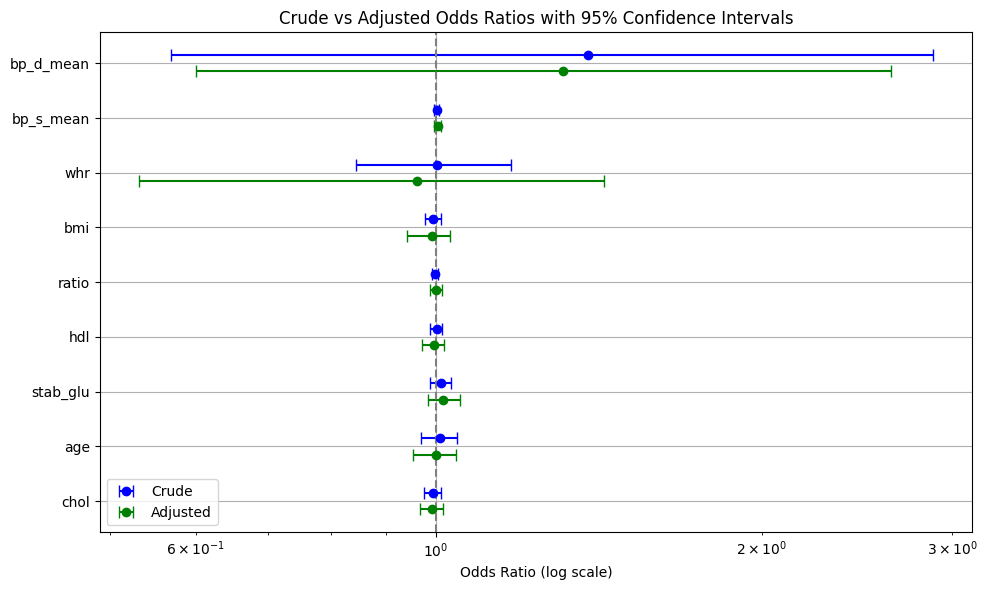

In [5]:
# Full model with all predictors
adjusted_or_results = []
for i, feature in enumerate(X.columns):
    or_vals = []
    for _ in range(1000):
        X_b, y_b = resample(X, y)
        model = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000)
        model.fit(X_b, y_b)
        or_vals.append(np.exp(model.coef_[0][i]))
    lower = np.percentile(or_vals, 2.5)
    upper = np.percentile(or_vals, 97.5)
    mean_or = np.mean(or_vals)
    adjusted_or_results.append({
        'Variable': feature,
        'Adjusted OR': mean_or,
        '95% CI Lower': lower,
        '95% CI Upper': upper
    })

adjusted_or_df = pd.DataFrame(adjusted_or_results)
print("\nMultivariable (Adjusted) ORs:")
print(adjusted_or_df)


# Plotting
crude_or_df['Type'] = 'Crude'
adjusted_or_df['Type'] = 'Adjusted'
crude_or_df = crude_or_df.rename(columns={'Crude OR': 'OR'})
adjusted_or_df = adjusted_or_df.rename(columns={'Adjusted OR': 'OR'})
or_combined_df = pd.concat([crude_or_df, adjusted_or_df])

plt.figure(figsize=(10, 6))
for i, (var, group) in enumerate(or_combined_df.groupby('Variable')):
    for j, row in group.iterrows():
        x = row['OR']
        ci_low = row['95% CI Lower']
        ci_up = row['95% CI Upper']
        plt.errorbar(x, i + (0.15 if row['Type'] == 'Crude' else -0.15),
                     xerr=[[x - ci_low], [ci_up - x]],
                     fmt='o', label=row['Type'] if i == 0 else "", 
                     capsize=4, color='blue' if row['Type'] == 'Crude' else 'green')

plt.axvline(1, linestyle='--', color='gray')
plt.yticks(range(len(or_combined_df['Variable'].unique())), or_combined_df['Variable'].unique())
plt.xlabel("Odds Ratio (log scale)")
plt.xscale('log')
plt.title("Crude vs Adjusted Odds Ratios with 95% Confidence Intervals")
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()


# IC

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Verifica il dataset (usa quello che hai definito prima)
X = df_model.drop(columns='diagnosis')  # Cambia se necessario
y = df_model['diagnosis'].astype(int)

print(f"Dataset shape: {X.shape}")
print(f"Target distribution: {y.value_counts()}")

def compute_or_ci(X, y, n_bootstraps=1000, alpha=0.05):
    """Calcola OR e CI con bootstrap"""
    or_vals = []
    
    for _ in range(n_bootstraps):  # CORREZIONE: _ invece di *
        X_b, y_b = resample(X, y, random_state=None)
        
        # Controllo per evitare casi degeneri
        if len(np.unique(y_b)) < 2:
            continue
            
        model = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000)
        
        try:
            model.fit(X_b, y_b)
            or_vals.append(np.exp(model.coef_[0][0]))
        except:
            continue
    
    if len(or_vals) == 0:
        return np.nan, np.nan, np.nan
    
    lower = np.percentile(or_vals, 100 * alpha / 2)
    upper = np.percentile(or_vals, 100 * (1 - alpha / 2))
    return np.mean(or_vals), lower, upper

# 1. CRUDE ORs (modelli univariabili)
print("=== CALCOLO OR CRUDE ===")
crude_or_results = []

for feature in X.columns:
    print(f"Analizzando {feature}...")
    X_i = X[[feature]]
    or_val, lower_ci, upper_ci = compute_or_ci(X_i, y)
    
    crude_or_results.append({
        'Variable': feature,
        'Crude_OR': or_val,
        'CI_Lower': lower_ci,
        'CI_Upper': upper_ci
    })

crude_or_df = pd.DataFrame(crude_or_results)
print("\nUnivariable (Crude) ORs:")
print(crude_or_df.round(3))

# 2. ADJUSTED ORs (modello multivariabile)
print("\n=== CALCOLO OR AGGIUSTATE ===")
adjusted_or_results = []

for i, feature in enumerate(X.columns):
    print(f"Analizzando {feature} (posizione {i})...")
    or_vals = []
    
    for _ in range(1000):
        X_b, y_b = resample(X, y, random_state=None)
        
        if len(np.unique(y_b)) < 2:
            continue
            
        model = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000)
        
        try:
            model.fit(X_b, y_b)
            or_vals.append(np.exp(model.coef_[0][i]))
        except:
            continue
    
    if len(or_vals) > 0:
        lower = np.percentile(or_vals, 2.5)
        upper = np.percentile(or_vals, 97.5)
        mean_or = np.mean(or_vals)
    else:
        lower = upper = mean_or = np.nan
    
    adjusted_or_results.append({
        'Variable': feature,
        'Adjusted_OR': mean_or,
        'CI_Lower': lower,
        'CI_Upper': upper
    })

adjusted_or_df = pd.DataFrame(adjusted_or_results)
print("\nMultivariable (Adjusted) ORs:")
print(adjusted_or_df.round(3))

Dataset shape: (377, 9)
Target distribution: diagnosis
0    319
1     58
Name: count, dtype: int64
=== CALCOLO OR CRUDE ===
Analizzando chol...
Analizzando age...
Analizzando stab_glu...
Analizzando hdl...
Analizzando ratio...
Analizzando bmi...
Analizzando whr...
Analizzando bp_s_mean...
Analizzando bp_d_mean...

Univariable (Crude) ORs:
    Variable  Crude_OR  CI_Lower  CI_Upper
0       chol     1.013     1.007     1.019
1        age     1.053     1.036     1.074
2   stab_glu     1.040     1.027     1.058
3        hdl     0.976     0.952     0.999
4      ratio     1.534     1.299     1.836
5        bmi     1.056     1.020     1.099
6        whr     5.103     2.106    10.514
7  bp_s_mean     1.022     1.011     1.037
8  bp_d_mean     1.013     0.992     1.032

=== CALCOLO OR AGGIUSTATE ===
Analizzando chol (posizione 0)...
Analizzando age (posizione 1)...
Analizzando stab_glu (posizione 2)...
Analizzando hdl (posizione 3)...
Analizzando ratio (posizione 4)...
Analizzando bmi (posizion

# Risk Factors

In [7]:
# Combina crude e adjusted in un'unica tabella
results_combined = crude_or_df.merge(
    adjusted_or_df, 
    on='Variable', 
    suffixes=('_crude', '_adj')
)

# Formato per pubblicazione
results_combined['Crude_OR_CI'] = results_combined.apply(
    lambda row: f"{row['Crude_OR']:.2f} ({row['CI_Lower_crude']:.2f}-{row['CI_Upper_crude']:.2f})", 
    axis=1
)

results_combined['Adjusted_OR_CI'] = results_combined.apply(
    lambda row: f"{row['Adjusted_OR']:.2f} ({row['CI_Lower_adj']:.2f}-{row['CI_Upper_adj']:.2f})", 
    axis=1
)

publication_table = results_combined[['Variable', 'Crude_OR_CI', 'Adjusted_OR_CI']]
print("\n=== TABELLA PER PUBBLICAZIONE ===")
print(publication_table)


=== TABELLA PER PUBBLICAZIONE ===
    Variable        Crude_OR_CI    Adjusted_OR_CI
0       chol   1.01 (1.01-1.02)  1.01 (0.99-1.03)
1        age   1.05 (1.04-1.07)  1.04 (1.01-1.08)
2   stab_glu   1.04 (1.03-1.06)  1.04 (1.02-1.07)
3        hdl   0.98 (0.95-1.00)  0.98 (0.91-1.04)
4      ratio   1.53 (1.30-1.84)  0.99 (0.46-1.90)
5        bmi   1.06 (1.02-1.10)  1.05 (0.98-1.12)
6        whr  5.10 (2.11-10.51)  1.22 (0.67-2.07)
7  bp_s_mean   1.02 (1.01-1.04)  1.00 (0.98-1.03)
8  bp_d_mean   1.01 (0.99-1.03)  1.02 (0.97-1.07)


In [8]:
# Identifica i fattori di rischio significativi
print("\n=== INTERPRETAZIONE EPIDEMIOLOGICA ===")

for _, row in results_combined.iterrows():
    var = row['Variable']
    crude_or = row['Crude_OR']
    adj_or = row['Adjusted_OR']
    
    # Check se CI include 1.0
    crude_significant = not (row['CI_Lower_crude'] <= 1.0 <= row['CI_Upper_crude'])
    adj_significant = not (row['CI_Lower_adj'] <= 1.0 <= row['CI_Upper_adj'])
    
    print(f"\n{var}:")
    print(f"  Crude OR: {crude_or:.2f} ({'Significativo' if crude_significant else 'Non significativo'})")
    print(f"  Adjusted OR: {adj_or:.2f} ({'Significativo' if adj_significant else 'Non significativo'})")
    
    # Interpretazione del cambiamento
    if not np.isnan(crude_or) and not np.isnan(adj_or):
        change = abs(crude_or - adj_or) / crude_or * 100
        if change > 10:
            print(f"  CONFOUNDING IMPORTANTE: cambio del {change:.1f}%")


=== INTERPRETAZIONE EPIDEMIOLOGICA ===

chol:
  Crude OR: 1.01 (Significativo)
  Adjusted OR: 1.01 (Non significativo)

age:
  Crude OR: 1.05 (Significativo)
  Adjusted OR: 1.04 (Significativo)

stab_glu:
  Crude OR: 1.04 (Significativo)
  Adjusted OR: 1.04 (Significativo)

hdl:
  Crude OR: 0.98 (Significativo)
  Adjusted OR: 0.98 (Non significativo)

ratio:
  Crude OR: 1.53 (Significativo)
  Adjusted OR: 0.99 (Non significativo)
  CONFOUNDING IMPORTANTE: cambio del 35.4%

bmi:
  Crude OR: 1.06 (Significativo)
  Adjusted OR: 1.05 (Non significativo)

whr:
  Crude OR: 5.10 (Significativo)
  Adjusted OR: 1.22 (Non significativo)
  CONFOUNDING IMPORTANTE: cambio del 76.2%

bp_s_mean:
  Crude OR: 1.02 (Significativo)
  Adjusted OR: 1.00 (Non significativo)

bp_d_mean:
  Crude OR: 1.01 (Non significativo)
  Adjusted OR: 1.02 (Non significativo)


# Modelli

In [9]:
from sklearn.model_selection import train_test_split
import numpy as np

# SPLIT STRATIFICATO (mantiene stessa prevalenza)
X_final = df_model_cleaned.drop(columns='diagnosis')
y_final = df_model_cleaned['diagnosis'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, 
    test_size=0.2, 
    stratify=y_final,
    random_state=42
)

print("=== VERIFICA STRATIFICAZIONE ===")
print(f"Dataset completo: {len(y_final)} obs, prevalenza: {y_final.mean():.3f}")
print(f"Training set: {len(y_train)} obs, prevalenza: {y_train.mean():.3f}")
print(f"Test set: {len(y_test)} obs, prevalenza: {y_test.mean():.3f}")
print(f"Differenza prevalenza: {abs(y_train.mean() - y_test.mean()):.4f}")

# SALVA i set per non contaminarli
print("\n⚠  IMPORTANTE: Il test set NON verrà più toccato fino alla validazione finale!")

=== VERIFICA STRATIFICAZIONE ===
Dataset completo: 354 obs, prevalenza: 0.153
Training set: 283 obs, prevalenza: 0.152
Test set: 71 obs, prevalenza: 0.155
Differenza prevalenza: 0.0030

⚠  IMPORTANTE: Il test set NON verrà più toccato fino alla validazione finale!


## Predictive models with interactions (Minimal, Metabolic, Complete)

This section adds three logistic regression models—**Minimal**, **Metabolic**, and **Complete**—enhanced with a small set of clinically sensible interaction terms:

* `age × chol`
* `age × hdl`
* `bmi × bp_s_mean`
* `age × bmi`

Workflow highlights  
* **Train/test split**: 80 % / 20 % &nbsp;·&nbsp; seed = 123  
* **CV**: 15‑fold stratified ROC‑AUC  
* **Performance on test set**: AUC, confusion‑matrix, sensitivity, specificity with **bootstrap 95 % CIs** (1000 repliche)  
* **Calibration** curve (reliability plot) & Brier score

> *Nota:* il codice assume che il *DataFrame* pre‑processato `df_model_cleaned` (con outcome binario `diagnosis`) sia già disponibile dalle celle precedenti.  
> In caso contrario lancia un errore che ricorda di eseguire prima il pre‑processing.

,Model,CV AUC (mean±SD),Threshold*,Test AUC (95% CI),Sensitivity (95% CI),Specificity (95% CI)
0,Minimal,0.530 ± 0.165,0.54,0.444 (0.240-0.662),0.182 (0.000-0.500),0.783 (0.683-0.879)
1,Metabolic,0.490 ± 0.146,0.56,0.423 (0.222-0.633),0.091 (0.000-0.308),0.800 (0.696-0.897)
2,Complete,0.544 ± 0.201,0.55,0.400 (0.233-0.589),0.182 (0.000-0.462),0.700 (0.576-0.818)


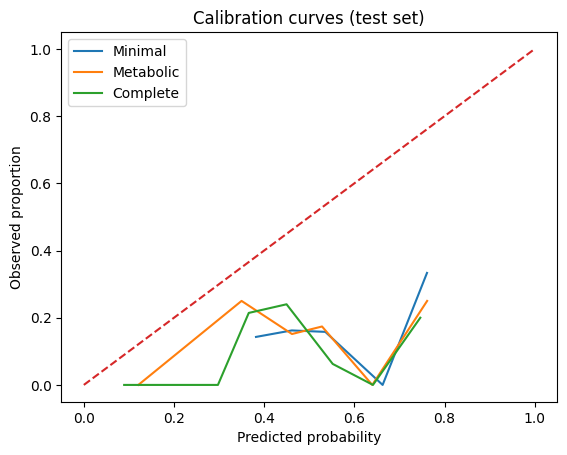

In [18]:

# %% Predictive models (balanced, scaled) with optimal threshold
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

RANDOM_STATE = 123

# ---------------------------------------------------------------
# Check dataset already prepared
# ---------------------------------------------------------------
try:
    data = df_model_cleaned.copy()
except NameError as e:
    raise RuntimeError('df_model_cleaned not found – run preprocessing first.') from e

# ---------------------------------------------------------------
# Feature sets & interactions
# ---------------------------------------------------------------
minimal_features   = ['age', 'stab_glu']
metabolic_features = ['age', 'stab_glu', 'hdl', 'chol']
complete_features  = ['age', 'stab_glu', 'hdl', 'chol', 'bmi', 'bp_s_mean']

interaction_pairs = [
    ('age', 'chol'),
    ('age', 'hdl'),
    ('bmi', 'bp_s_mean'),
    ('age', 'bmi')
]

def add_interactions(df, pairs):
    out = df.copy()
    for a, b in pairs:
        out[f'{a}_x_{b}'] = out[a] * out[b]
    return out

data = add_interactions(data, interaction_pairs)

# ---------------------------------------------------------------
# Train / test split (stratified)
# ---------------------------------------------------------------
X = data.drop(columns='diagnosis')
y = data['diagnosis'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# ---------------------------------------------------------------
# Helper: compute optimal threshold on TRAIN by Youden J index
# ---------------------------------------------------------------
def optimal_threshold(model, X_val, y_val):
    y_prob_val = model.predict_proba(X_val)[:, 1]
    fpr, tpr, thr = roc_curve(y_val, y_prob_val)
    J = tpr - fpr
    best_idx = np.argmax(J)
    return thr[best_idx]

# ---------------------------------------------------------------
# Models dictionary
# ---------------------------------------------------------------
models = {
    'Minimal'  : minimal_features,
    'Metabolic': metabolic_features + ['age_x_chol', 'age_x_hdl'],
    'Complete' : complete_features + ['age_x_chol', 'age_x_hdl', 'bmi_x_bp_s_mean', 'age_x_bmi']
}

cv = StratifiedKFold(n_splits=15, shuffle=True, random_state=RANDOM_STATE)
results = {}

for name, feats in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=1000, solver='liblinear', class_weight='balanced'))
    ])
    # Cross‑val AUC on TRAIN
    cv_auc = cross_val_score(pipe, X_train[feats], y_train, cv=cv, scoring='roc_auc')
    # Fit on full TRAIN
    pipe.fit(X_train[feats], y_train)
    # Determine optimal threshold on TRAIN
    thr_opt = optimal_threshold(pipe, X_train[feats], y_train)

    # Test predictions
    y_prob_test = pipe.predict_proba(X_test[feats])[:, 1]
    y_pred_test = (y_prob_test >= thr_opt).astype(int)
    cm = confusion_matrix(y_test, y_pred_test)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0
    spec = tn / (tn + fp) if (tn + fp) else 0

    # Store
    results[name] = {
        'features'     : feats,
        'model'        : pipe,
        'threshold'    : thr_opt,
        'cv_auc_mean'  : cv_auc.mean(),
        'cv_auc_std'   : cv_auc.std(ddof=1),
        'test_auc'     : roc_auc_score(y_test, y_prob_test),
        'test_cm'      : cm,
        'test_sens'    : sens,
        'test_spec'    : spec,
        'calibration'  : calibration_curve(y_test, y_prob_test, n_bins=10, strategy='uniform')
    }

# ---------------------------------------------------------------
# Bootstrap 95 % CI on TEST
# ---------------------------------------------------------------
n_boot = 1000
rng = np.random.RandomState(RANDOM_STATE)

for name, info in results.items():
    feats = info['features']
    model = info['model']
    thr   = info['threshold']

    boot_auc, boot_sens, boot_spec = [], [], []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y_test), len(y_test))
        y_true_bs = y_test.iloc[idx].values
        X_bs      = X_test.iloc[idx][feats]
        y_prob_bs = model.predict_proba(X_bs)[:, 1]
        y_pred_bs = (y_prob_bs >= thr).astype(int)

        boot_auc.append(roc_auc_score(y_true_bs, y_prob_bs))
        tn, fp, fn, tp = confusion_matrix(y_true_bs, y_pred_bs).ravel()
        boot_sens.append(tp / (tp + fn) if (tp + fn) else np.nan)
        boot_spec.append(tn / (tn + fp) if (tn + fp) else np.nan)

    info['ci_auc']  = (np.nanpercentile(boot_auc, 2.5),  np.nanpercentile(boot_auc, 97.5))
    info['ci_sens'] = (np.nanpercentile(boot_sens, 2.5), np.nanpercentile(boot_sens, 97.5))
    info['ci_spec'] = (np.nanpercentile(boot_spec, 2.5), np.nanpercentile(boot_spec, 97.5))

# ---------------------------------------------------------------
# Summary table
# ---------------------------------------------------------------
summary = pd.DataFrame([
    {
        'Model'              : k,
        'CV AUC (mean±SD)'   : f"{v['cv_auc_mean']:.3f} ± {v['cv_auc_std']:.3f}",
        'Threshold*'         : f"{v['threshold']:.2f}",
        'Test AUC (95% CI)'  : f"{v['test_auc']:.3f} ({v['ci_auc'][0]:.3f}-{v['ci_auc'][1]:.3f})",
        'Sensitivity (95% CI)': f"{v['test_sens']:.3f} ({v['ci_sens'][0]:.3f}-{v['ci_sens'][1]:.3f})",
        'Specificity (95% CI)': f"{v['test_spec']:.3f} ({v['ci_spec'][0]:.3f}-{v['ci_spec'][1]:.3f})"
    }
    for k, v in results.items()
])

display(summary.style.set_caption("*Threshold selected on training set via Youden J index"))

# ---------------------------------------------------------------
# Calibration curves
# ---------------------------------------------------------------
plt.figure()
for name, info in results.items():
    prob_true, prob_pred = info['calibration']
    plt.plot(prob_pred, prob_true, label=name)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Predicted probability')
plt.ylabel('Observed proportion')
plt.title('Calibration curves (test set)')
plt.legend()
plt.show()


In [ ]:

# %% Minimal model (age + stab_glu) replicating R pipeline without regularization
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve, RocCurveDisplay, accuracy_score
import matplotlib.pyplot as plt

RANDOM_STATE = 123

try:
    data = df_model_cleaned.copy()
except NameError:
    raise RuntimeError('Run preprocessing first to obtain df_model_cleaned')

# optional: ensure column naming as in R
if 'stab.glu' in data.columns and 'stab_glu' not in data.columns:
    data.rename(columns={'stab.glu':'stab_glu'}, inplace=True)

X = data[['age','stab_glu']]
y = data['diagnosis'].astype(int)

# Shuffle rows (equivalent to sample_frac in R)
data_shuffled = data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
X = data_shuffled[['age','stab_glu']]
y = data_shuffled['diagnosis'].astype(int)

# Stratified split 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Pipeline: scale + logistic regression without regularization
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(penalty=None, solver='lbfgs', max_iter=2000))
])

# 15-fold CV AUC
cv = StratifiedKFold(n_splits=15, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_val_score
cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"CV AUC mean ± sd: {cv_auc.mean():.3f} ± {cv_auc.std(ddof=1):.3f}")

# Fit
pipe.fit(X_train, y_train)

# Predict on test
y_prob = pipe.predict_proba(X_test)[:,1]
y_pred = (y_prob >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Test AUC:", test_auc)
print("Confusion matrix:\n", cm)
print("Sensitivity:", tp/(tp+fn))
print("Specificity:", tn/(tn+fp))
print("Accuracy:", accuracy_score(y_test, y_pred))

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve (Minimal, penalty='none')")
plt.show()

ValueError: 
All the 15 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\david\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\david\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\david\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\pipeline.py", line 473, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "c:\Users\david\AppData\Local\Progr

In [14]:
print(y.value_counts())
print(y_test.value_counts())       # quante classi nel test?


diagnosis
0    300
1     54
Name: count, dtype: int64
diagnosis
0    60
1    11
Name: count, dtype: int64


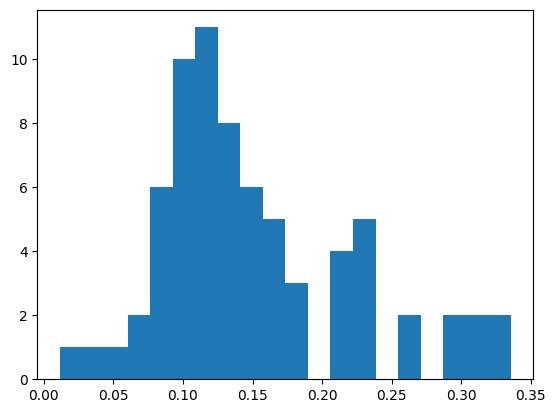

In [15]:
plt.hist(y_prob, bins=20);         # dovrebbero vedersi valori >0.5
